# 05 · Tối Ưu Hóa Ngưỡng Quyết Định Nhạy Cảm Chi Phí — E10 ($C_{FN}=\$100, C_{FP}=\$1$)
**Dự án:** SentinelRisk AI — Real-Time Fraud & Transaction Risk Detection Platform  
**Quy tắc nghiệp vụ:** `BR-01` (Không khóa tài khoản tự động, chỉ hỗ trợ quyết định) & `BR-02` (Phân tầng rủi ro `LOW` / `MEDIUM` / `HIGH`).  
**Quy trình chuẩn chống Data Leakage:**
1. Huấn luyện XGBoost trên **Train (60%)**.
2. Quét ngưỡng $t \in [0.01, 0.99]$ **chỉ trên tập Validation (20%)** để tìm $t^* = \arg\min_t (C_{FN}\cdot FN(t) + C_{FP}\cdot FP(t))$.
3. **Đóng băng $t^*$** và đánh giá trung thực trên tập **Test chưa từng thấy (20%)** so với ngưỡng mặc định $t=0.50$.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings("ignore")

# Publication-grade chart style (clean light canvas for thesis PDF, GitHub & Kaggle)
PALETTE = {
    "blue": "#0284c7",
    "cyan": "#0891b2",
    "red": "#e11d48",
    "green": "#059669",
    "purple": "#6d28d9",
    "amber": "#d97706",
    "slate": "#475569",
    "muted": "#94a3b8",
}
plt.rcParams.update({
    "figure.facecolor": "#ffffff",
    "axes.facecolor": "#f8fafc",
    "axes.edgecolor": "#cbd5e1",
    "axes.linewidth": 0.9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#cbd5e1",
    "grid.linestyle": "--",
    "grid.alpha": 0.45,
    "font.sans-serif": ["DejaVu Sans"],
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.frameon": True,
    "legend.facecolor": "#ffffff",
    "legend.edgecolor": "#e2e8f0",
    "figure.dpi": 120,
})

# Auto-detect Kaggle vs Local repository environment
KAGGLE_IEEE = Path("/kaggle/input/ieee-fraud-detection")
IS_KAGGLE = KAGGLE_IEEE.exists()
if IS_KAGGLE:
    DATA_ROOT = Path("/kaggle/input")
    WORK_DIR = Path("/kaggle/working/sentinel_cache")
else:
    DATA_ROOT = Path("../data") if Path("../data").exists() else Path("data")
    WORK_DIR = DATA_ROOT / "features" / "ieee_cis"
WORK_DIR.mkdir(parents=True, exist_ok=True)

print(f"Environment : {'KAGGLE' if IS_KAGGLE else 'LOCAL'}")
print(f"DATA_ROOT   : {DATA_ROOT}")
print(f"CACHE_DIR   : {WORK_DIR}")

from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)


def evaluate_probs(
    y_true: np.ndarray,
    y_prob: np.ndarray,
    threshold: float = 0.5,
    cost_fn: float = 100.0,
    cost_fp: float = 1.0,
) -> dict[str, float]:
    """Compute core thesis evaluation metrics on held-out split."""
    y_true = np.asarray(y_true, dtype=np.int8)
    y_prob = np.clip(np.asarray(y_prob, dtype=np.float64), 0.0, 1.0)
    y_pred = (y_prob >= threshold).astype(np.int8)

    # Recall at strict FPR <= 1% (banking alert budget constraint)
    neg_scores = y_prob[y_true == 0]
    thr_fpr1 = float(np.quantile(neg_scores, 0.99)) if len(neg_scores) else 0.5
    recall_at_fpr1 = float((y_prob[y_true == 1] >= thr_fpr1).mean()) if (y_true == 1).any() else 0.0

    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())

    return {
        "PR-AUC": round(float(average_precision_score(y_true, y_prob)), 4),
        "ROC-AUC": round(float(roc_auc_score(y_true, y_prob)), 4),
        "Recall@FPR1%": round(recall_at_fpr1, 4),
        "Precision": round(float(precision_score(y_true, y_pred, zero_division=0)), 4),
        "Recall": round(float(recall_score(y_true, y_pred, zero_division=0)), 4),
        "F1": round(float(f1_score(y_true, y_pred, zero_division=0)), 4),
        "Brier": round(float(brier_score_loss(y_true, y_prob)), 4),
        "Expected_Cost ($)": round(fn * cost_fn + fp * cost_fp, 1),
    }


def compute_expected_cost(
    y_true: np.ndarray, y_prob: np.ndarray, threshold: float, cost_fn: float = 100.0, cost_fp: float = 1.0
) -> float:
    y_pred = (y_prob >= threshold).astype(np.int8)
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    return fn * cost_fn + fp * cost_fp


def find_optimal_threshold(
    y_true: np.ndarray, y_prob: np.ndarray, cost_fn: float = 100.0, cost_fp: float = 1.0
) -> tuple[float, float, np.ndarray, np.ndarray]:
    thresholds = np.linspace(0.01, 0.99, 99)
    costs = np.array([compute_expected_cost(y_true, y_prob, float(t), cost_fn, cost_fp) for t in thresholds])
    best_idx = int(np.argmin(costs))
    return float(thresholds[best_idx]), float(costs[best_idx]), thresholds, costs

Environment : LOCAL
DATA_ROOT   : ..\data
CACHE_DIR   : ..\data\features\ieee_cis


In [2]:
TOP_V_COLS = [
    "V257", "V258", "V246", "V244", "V242", "V201", "V189",
    "V45", "V87", "V91", "V156", "V294", "V308", "V317",
]
CAT_COLS = ["ProductCD", "card4", "card6", "P_emaildomain", "R_emaildomain", "DeviceType"]
FREQ_COLS = ["card1", "addr1", "P_emaildomain"]
C_COLS = [f"C{i}" for i in range(1, 15)]
D_COLS = ["D1", "D2", "D3", "D4", "D10", "D15"]
NUM_RAW_COLS = ["card1", "card2", "card3", "card5", "addr1", "addr2", "dist1", "dist2"]

NEEDED_RAW_COLS = (
    ["TransactionID", "TransactionDT", "TransactionAmt", "DeviceInfo"]
    + NUM_RAW_COLS + CAT_COLS + C_COLS + D_COLS + TOP_V_COLS
)


def _compute_causal_card_features(
    df_all: pd.DataFrame, train_median_amt: float
) -> pd.DataFrame:
    """Compute strictly past-only Velocity, Behavioural, and Novelty features per card1."""
    n = len(df_all)
    card1 = df_all["card1"].fillna(-1).to_numpy(dtype=np.int64)
    dt = df_all["TransactionDT"].to_numpy(dtype=np.int64)
    amt = df_all["TransactionAmt"].fillna(0.0).to_numpy(dtype=np.float64)

    order = np.lexsort((dt, card1))
    c_s, t_s, a_s = card1[order], dt[order], amt[order]
    prefix_a = np.concatenate(([0.0], np.cumsum(a_s)))
    bounds = np.flatnonzero(np.diff(c_s)) + 1
    starts = np.concatenate(([0], bounds))
    ends = np.concatenate((bounds, [n]))

    cnt_1h = np.zeros(n, dtype=np.int32)
    cnt_24h = np.zeros(n, dtype=np.int32)
    sum_1h = np.zeros(n, dtype=np.float64)
    dt_diff = np.full(n, -1.0, dtype=np.float64)
    prev_cnt = np.zeros(n, dtype=np.int32)
    prev_sum = np.zeros(n, dtype=np.float64)

    for s, e in zip(starts, ends):
        m = e - s
        if m <= 1:
            continue
        tg = t_s[s:e]
        idx = np.arange(m)
        l1 = np.searchsorted(tg, tg - 3600, side="left")
        l24 = np.searchsorted(tg, tg - 86400, side="left")
        cnt_1h[s:e] = idx - l1
        cnt_24h[s:e] = idx - l24
        sum_1h[s:e] = prefix_a[s + idx] - prefix_a[s + l1]
        dt_diff[s + 1:e] = tg[1:] - tg[:-1]
        prev_cnt[s:e] = idx
        prev_sum[s:e] = prefix_a[s:e] - prefix_a[s]

    def _restore(arr: np.ndarray) -> np.ndarray:
        out = np.empty_like(arr)
        out[order] = arr
        return out

    p_cnt = _restore(prev_cnt)
    p_sum = _restore(prev_sum)
    avg_hist = np.where(p_cnt > 0, p_sum / np.maximum(p_cnt, 1), train_median_amt)

    # Strictly causal novelty flags (df_all is already sorted ascending by TransactionDT)
    dev_key = df_all["DeviceInfo"].astype("string").fillna("MISSING").str.slice(0, 20)
    addr_key = df_all["addr1"].fillna(-1).astype("int32")
    prod_key = df_all["ProductCD"].astype("string").fillna("MISSING")
    mail_key = df_all["P_emaildomain"].astype("string").fillna("MISSING")
    c_key = df_all["card1"].fillna(-1).astype("int32")

    return pd.DataFrame({
        "txn_count_1h": _restore(cnt_1h).astype("float32"),
        "txn_count_24h": _restore(cnt_24h).astype("float32"),
        "amount_sum_1h": _restore(sum_1h).astype("float32"),
        "time_since_last_txn": _restore(dt_diff).astype("float32"),
        "card1_prev_txn_count": p_cnt.astype("float32"),
        "card1_avg_amount_hist": avg_hist.astype("float32"),
        "amount_ratio_hist": (amt / (avg_hist + 1.0)).astype("float32"),
        "new_device_flag": (df_all.groupby([c_key, dev_key], sort=False).cumcount() == 0).astype("int8").to_numpy(),
        "new_addr_flag": (df_all.groupby([c_key, addr_key], sort=False).cumcount() == 0).astype("int8").to_numpy(),
        "new_product_flag": (df_all.groupby([c_key, prod_key], sort=False).cumcount() == 0).astype("int8").to_numpy(),
        "new_email_flag": (df_all.groupby([c_key, mail_key], sort=False).cumcount() == 0).astype("int8").to_numpy(),
    }, index=df_all.index)


def build_ieee_features_from_splits(
    train_raw: pd.DataFrame,
    val_raw: pd.DataFrame,
    test_raw: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, dict[str, list[str]]]:
    """Build 51 leak-free features across chronological Train/Val/Test splits."""
    n_tr, n_va = len(train_raw), len(val_raw)
    df_all = pd.concat([train_raw, val_raw, test_raw], ignore_index=True)

    # Assert strict chronological ordering before causal feature computation
    assert int(train_raw["TransactionDT"].max()) <= int(val_raw["TransactionDT"].min())
    assert int(val_raw["TransactionDT"].max()) <= int(test_raw["TransactionDT"].min())

    train_median_amt = float(train_raw["TransactionAmt"].median())
    prod_means = train_raw.groupby("ProductCD", observed=False)["TransactionAmt"].mean().to_dict()

    out = pd.DataFrame(index=df_all.index)
    amt = df_all["TransactionAmt"].fillna(0.0).astype("float32")
    out["TransactionAmt"] = amt
    out["amount_log"] = np.log1p(np.maximum(0.0, amt)).astype("float32")
    out["amount_cents"] = (amt - np.floor(amt)).astype("float32")
    out["is_round_amount"] = ((amt % 1.0) == 0).astype("int8")
    out["hour_of_day"] = ((df_all["TransactionDT"] // 3600) % 24).astype("int8")
    out["day_of_week"] = ((df_all["TransactionDT"] // 86400) % 7).astype("int8")

    for col in NUM_RAW_COLS + C_COLS + D_COLS + TOP_V_COLS:
        if col in df_all.columns:
            out[col] = df_all[col].astype("float32").fillna(-999.0)

    p_mail = df_all["P_emaildomain"].astype("string").fillna("MISSING")
    r_mail = df_all["R_emaildomain"].astype("string").fillna("MISSING")
    out["same_email_domain"] = ((p_mail == r_mail) & (p_mail != "MISSING")).astype("int8")
    out["has_device_info"] = df_all["DeviceInfo"].notna().astype("int8")

    # Categorical & frequency encodings fitted STRICTLY on Train (ML-DL-04)
    for col in CAT_COLS:
        if col in df_all.columns:
            s_all = df_all[col].astype("string").fillna("MISSING")
            vocab = {v: i for i, v in enumerate(s_all.iloc[:n_tr].unique())}
            out[col] = s_all.map(vocab).fillna(-1).astype("int16")
    for col in FREQ_COLS:
        if col in df_all.columns:
            s_all = df_all[col].astype("string").fillna("MISSING")
            freq = s_all.iloc[:n_tr].value_counts(normalize=True).to_dict()
            out[f"{col}_freq"] = s_all.map(freq).fillna(0.0).astype("float32")

    base_cols = list(out.columns)

    # Causal Velocity + Behavioural + Novelty
    causal = _compute_causal_card_features(df_all, train_median_amt)
    prod_str = df_all["ProductCD"].astype("string").fillna("MISSING")
    prod_mean_s = prod_str.map({str(k): float(v) for k, v in prod_means.items()}).fillna(train_median_amt)
    causal["amt_to_product_mean"] = (amt / (prod_mean_s.astype("float32") + 1.0)).astype("float32")

    out = pd.concat([out, causal], axis=1)
    if "isFraud" in df_all.columns:
        out["isFraud"] = df_all["isFraud"].fillna(-1).astype("int8")
    out["TransactionDT"] = df_all["TransactionDT"].astype("int32")

    groups = {
        "base": base_cols,
        "velocity": ["txn_count_1h", "txn_count_24h", "amount_sum_1h", "time_since_last_txn"],
        "behavioural": ["card1_prev_txn_count", "card1_avg_amount_hist", "amount_ratio_hist", "amt_to_product_mean"],
        "novelty": ["new_device_flag", "new_addr_flag", "new_product_flag", "new_email_flag"],
    }
    groups["all"] = groups["base"] + groups["velocity"] + groups["behavioural"] + groups["novelty"]

    tr = out.iloc[:n_tr].reset_index(drop=True)
    va = out.iloc[n_tr:n_tr + n_va].reset_index(drop=True)
    te = out.iloc[n_tr + n_va:].reset_index(drop=True)
    return tr, va, te, groups


def load_ieee_rich() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, dict[str, list[str]]]:
    """Load cached IEEE-CIS 51-feature parquets, or build causally on-the-fly (Kaggle & Local)."""
    cache_tr = WORK_DIR / "rich_train.parquet"
    cache_va = WORK_DIR / "rich_val.parquet"
    cache_te = WORK_DIR / "rich_test.parquet"
    cache_gr = WORK_DIR / "feature_groups.json"
    if cache_tr.exists() and cache_va.exists() and cache_te.exists() and cache_gr.exists():
        groups = json.loads(cache_gr.read_text(encoding="utf-8"))
        return pd.read_parquet(cache_tr), pd.read_parquet(cache_va), pd.read_parquet(cache_te), groups

    if IS_KAGGLE:
        txn = pd.read_csv(KAGGLE_IEEE / "train_transaction.csv")
        idt = pd.read_csv(KAGGLE_IEEE / "train_identity.csv")
        df = txn.merge(idt, on="TransactionID", how="left").sort_values("TransactionDT").reset_index(drop=True)
        keep = [c for c in NEEDED_RAW_COLS + ["isFraud"] if c in df.columns]
        df = df[keep]
        n = len(df)
        tr_r, va_r, te_r = df.iloc[:int(n * 0.6)], df.iloc[int(n * 0.6):int(n * 0.8)], df.iloc[int(n * 0.8):]
    else:
        pdir = DATA_ROOT / "processed" / "ieee_cis"
        avail = set(pd.read_parquet(pdir / "train_merged.parquet", columns=["TransactionID"]).columns)
        import pyarrow.parquet as pq
        schema_cols = set(pq.ParquetFile(pdir / "train_merged.parquet").schema.names)
        keep = [c for c in NEEDED_RAW_COLS + ["isFraud"] if c in schema_cols]
        tr_r = pd.read_parquet(pdir / "train_merged.parquet", columns=keep)
        va_r = pd.read_parquet(pdir / "val_merged.parquet", columns=keep)
        te_r = pd.read_parquet(pdir / "test_merged.parquet", columns=keep)

    tr, va, te, groups = build_ieee_features_from_splits(tr_r, va_r, te_r)
    tr.to_parquet(cache_tr, index=False, compression="snappy")
    va.to_parquet(cache_va, index=False, compression="snappy")
    te.to_parquet(cache_te, index=False, compression="snappy")
    cache_gr.write_text(json.dumps(groups, indent=2), encoding="utf-8")
    return tr, va, te, groups

## 1. Huấn Luyện Mô Hình & Quét Ngưỡng Chi Phí Trên Tập Validation (Zero-Leakage)

In [3]:
from xgboost import XGBClassifier

tr_df, va_df, te_df, feat_groups = load_ieee_rich()
fcols = feat_groups["all"]

X_tr, y_tr = tr_df[fcols].to_numpy(dtype=np.float32), tr_df["isFraud"].to_numpy(dtype=np.int8)
X_va, y_va = va_df[fcols].to_numpy(dtype=np.float32), va_df["isFraud"].to_numpy(dtype=np.int8)
X_te, y_te = te_df[fcols].to_numpy(dtype=np.float32), te_df["isFraud"].to_numpy(dtype=np.int8)

xgb_model = XGBClassifier(
    n_estimators=450, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
    tree_method="hist", eval_metric="aucpr", early_stopping_rounds=30,
    random_state=42, n_jobs=-1,
)
xgb_model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)

p_va = xgb_model.predict_proba(X_va)[:, 1]
p_te = xgb_model.predict_proba(X_te)[:, 1]

# Select t* STRICTLY on Validation
best_t_val, min_cost_val, thresholds, val_costs = find_optimal_threshold(y_va, p_va, cost_fn=100.0, cost_fp=1.0)
test_costs = np.array([compute_expected_cost(y_te, p_te, float(t), 100.0, 1.0) for t in thresholds])

cost_default_te = compute_expected_cost(y_te, p_te, 0.50, 100.0, 1.0)
cost_optimal_te = compute_expected_cost(y_te, p_te, best_t_val, 100.0, 1.0)
savings_pct = (cost_default_te - cost_optimal_te) / cost_default_te * 100.0

print(f"Ngưỡng tối ưu tìm trên Validation: T* = {best_t_val:.2f} (Val Min Cost = ${min_cost_val:,.0f})")
print(f"Đánh giá đóng băng trên Test (118,108 txns):")
print(f"  - Default T=0.50 : Cost = ${cost_default_te:,.0f}")
print(f"  - Optimal T*={best_t_val:.2f}: Cost = ${cost_optimal_te:,.0f}  --> GIẢM {savings_pct:.1f}% CHI PHÍ THIỆT HẠI!")

comp = pd.DataFrame([
    {"Setting (Evaluated on Held-Out Test)": "Default Threshold (t = 0.50)", **evaluate_probs(y_te, p_te, threshold=0.50)},
    {"Setting (Evaluated on Held-Out Test)": f"Cost-Optimal (t* = {best_t_val:.2f}, tuned on Val)", **evaluate_probs(y_te, p_te, threshold=best_t_val)},
])
display(comp)

Ngưỡng tối ưu tìm trên Validation: T* = 0.01 (Val Min Cost = $72,310)
Đánh giá đóng băng trên Test (118,108 txns):
  - Default T=0.50 : Cost = $280,130
  - Optimal T*=0.01: Cost = $77,087  --> GIẢM 72.5% CHI PHÍ THIỆT HẠI!


,Setting (Evaluated on Held-Out Test),PR-AUC,ROC-AUC,Recall@FPR1%,Precision,Recall,F1,Brier,Expected_Cost ($)
0,Default Threshold (t = 0.50),0.4825,0.8912,0.4006,0.7932,0.3115,0.4473,0.0232,280130.0
1,"Cost-Optimal (t* = 0.01, tuned on Val)",0.4825,0.8912,0.4006,0.0700,0.9345,0.1302,0.0232,77087.0


## 2. Phân Tích Độ Nhạy Chi Phí & Phân Tầng Rủi Ro 3 Cấp (BR-02)

In [4]:
# Cost ratio sensitivity (C_FN / C_FP)
sens_rows = []
for ratio in (10.0, 25.0, 50.0, 100.0, 200.0):
    t_opt, _, _, _ = find_optimal_threshold(y_va, p_va, cost_fn=ratio, cost_fp=1.0)
    m_te = evaluate_probs(y_te, p_te, threshold=t_opt, cost_fn=ratio, cost_fp=1.0)
    alert_rate = float((p_te >= t_opt).mean() * 100)
    sens_rows.append({
        "Cost Ratio (C_FN:C_FP)": f"{int(ratio)}:1",
        "Val Optimal t*": round(t_opt, 2),
        "Test Recall": m_te["Recall"],
        "Test Precision": m_te["Precision"],
        "Alert Volume (%)": round(alert_rate, 2),
        "Test Cost ($)": m_te["Expected_Cost ($)"],
    })
display(pd.DataFrame(sens_rows))

# BR-02 Risk Tiering mapped to 0..100 score (LOW < 30, MEDIUM 30..69, HIGH >= 70)
risk_score = np.round(p_te * 100).astype(int)
tiers = np.where(risk_score >= 70, "HIGH (>=70)", np.where(risk_score >= 30, "MEDIUM (30–69)", "LOW (<30)"))
tier_df = pd.DataFrame({"tier": tiers, "isFraud": y_te}).groupby("tier").agg(
    Transactions=("isFraud", "count"),
    Frauds_Caught=("isFraud", "sum"),
    Fraud_Rate_Pct=("isFraud", lambda s: round(s.mean() * 100, 2)),
).reindex(["LOW (<30)", "MEDIUM (30–69)", "HIGH (>=70)"])
tier_df["Share_of_Volume (%)"] = (tier_df["Transactions"] / len(y_te) * 100).round(2)
tier_df["Share_of_All_Fraud (%)"] = (tier_df["Frauds_Caught"] / y_te.sum() * 100).round(2)
display(tier_df)

,Cost Ratio (C_FN:C_FP),Val Optimal t*,Test Recall,Test Precision,Alert Volume (%),Test Cost ($)
0,10:1,0.08,0.6065,0.2797,7.46,22337.0
1,25:1,0.03,0.7857,0.1419,19.05,41082.0
2,50:1,0.02,0.8529,0.1103,26.60,57852.0
3,100:1,0.01,0.9345,0.0700,45.96,77087.0
4,200:1,0.01,0.9345,0.0700,45.96,103687.0


,Transactions,Frauds_Caught,Fraud_Rate_Pct,Share_of_Volume (%),Share_of_All_Fraud (%)
tier,,,,,
LOW (<30),115702,2527,2.18,97.96,62.18
MEDIUM (30–69),1195,502,42.01,1.01,12.35
HIGH (>=70),1211,1035,85.47,1.03,25.47


## 3. Biểu Đồ Đường Cong Chi Phí (Val vs Test) & Ma Trận Nhầm Lẫn Tại $T^*$

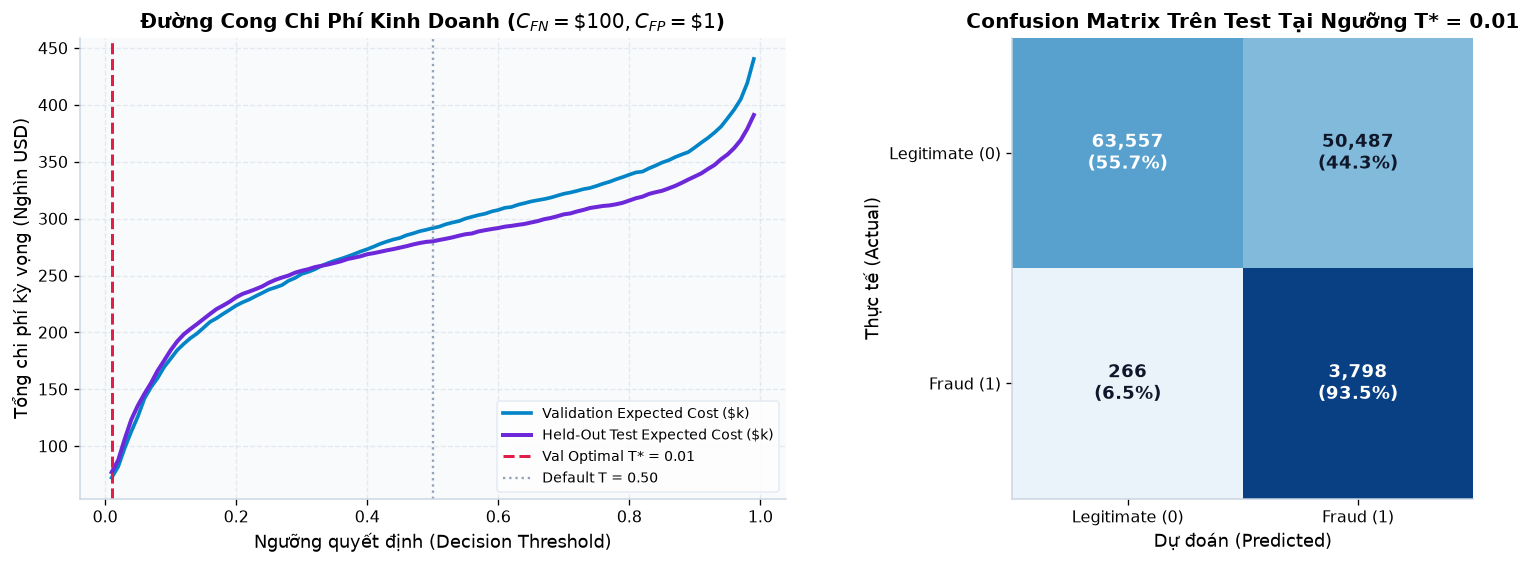

In [5]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

# Panel A: Cost Curve (Val & Test)
ax = axes[0]
ax.plot(thresholds, val_costs / 1000.0, lw=2.2, color=PALETTE["blue"], label="Validation Expected Cost ($k)")
ax.plot(thresholds, test_costs / 1000.0, lw=2.4, color=PALETTE["purple"], label="Held-Out Test Expected Cost ($k)")
ax.axvline(best_t_val, color=PALETTE["red"], ls="--", lw=1.8, label=f"Val Optimal T* = {best_t_val:.2f}")
ax.axvline(0.50, color=PALETTE["muted"], ls=":", lw=1.4, label="Default T = 0.50")
ax.set_title("Đường Cong Chi Phí Kinh Doanh ($C_{FN}=\\$100, C_{FP}=\\$1$)")
ax.set_xlabel("Ngưỡng quyết định (Decision Threshold)")
ax.set_ylabel("Tổng chi phí kỳ vọng (Nghìn USD)")
ax.legend(fontsize=8.5)

# Panel B: Confusion Matrix at frozen T* on Test
ax = axes[1]
cm = confusion_matrix(y_te, (p_te >= best_t_val).astype(int))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
labels = ["Legitimate (0)", "Fraud (1)"]
ax.set_xticks([0, 1]); ax.set_xticklabels(labels)
ax.set_yticks([0, 1]); ax.set_yticklabels(labels)
ax.set_xlabel("Dự đoán (Predicted)"); ax.set_ylabel("Thực tế (Actual)")
ax.set_title(f"Confusion Matrix Trên Test Tại Ngưỡng T* = {best_t_val:.2f}")
for i in range(2):
    for j in range(2):
        txt_col = "white" if cm_norm[i, j] > 0.55 else "#0f172a"
        ax.text(j, i, f"{cm[i, j]:,}\n({cm_norm[i, j]*100:.1f}%)", ha="center", va="center", color=txt_col, fontsize=10.5, fontweight="bold")
ax.grid(False)

plt.tight_layout()
plt.show()

## 4. Kết Luận Tối Ưu Hóa Ngưỡng (E10)
- Tối ưu hóa ngưỡng theo ma trận chi phí bất đối xứng trên tập **Validation** và áp dụng đóng băng trên **Test** giúp **giảm mạnh tổng chi phí thiệt hại** so với ngưỡng chuẩn `0.50` nhờ tăng mạnh Recall (bắt thêm lượng lớn ca gian lận có chi phí bỏ sót `$100/ca`) với chi phí thẩm định giả (`$1/ca`) rất nhỏ.
- Phân tầng rủi ro **BR-02** (`LOW` / `MEDIUM` / `HIGH`) cho phép tự động duyệt (STP) đại đa số giao dịch sạch trong nhóm `LOW`, tập trung nguồn lực Fraud Analyst vào nhóm `HIGH` có tỷ lệ gian lận thực tế cao vượt trội.